### libraries, dataset, utils,...

In [ ]:
import pathlib
import tensorflow as tf
import keras
from keras import layers, models
import os
import librosa
import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import seaborn as sns


In [ ]:
%%shell

wget http://download.tensorflow.org/data/speech_commands_v0.02.tar.gz
mkdir speech_commands
tar -xvzf speech_commands_v0.02.tar.gz -C speech_commands

Streaming output truncated to the last 5000 lines.
./on/fc3ba625_nohash_0.wav
./on/db9d52d2_nohash_0.wav
./on/72242187_nohash_4.wav
./on/b0f5b16d_nohash_0.wav
./on/d9aa8c90_nohash_1.wav
./on/525eaa62_nohash_0.wav
./on/42e3f068_nohash_0.wav
./on/94d370bf_nohash_4.wav
./on/bf8d5617_nohash_0.wav
./on/e2b7d6d6_nohash_2.wav
./on/89ed36ab_nohash_0.wav
./on/30276d03_nohash_1.wav
./on/364c0853_nohash_0.wav
./on/7cbf645a_nohash_0.wav
./on/c98bbbd3_nohash_2.wav
./on/9a7c1f83_nohash_5.wav
./on/3589bc72_nohash_0.wav
./on/3ae5c04f_nohash_0.wav
./on/adc216c5_nohash_2.wav
./on/c50f55b8_nohash_15.wav
./on/324210dd_nohash_2.wav
./on/c120e80e_nohash_2.wav
./on/69086eb0_nohash_0.wav
./on/dce05676_nohash_1.wav
./on/435695e3_nohash_1.wav
./on/179a61b7_nohash_1.wav
./on/f5341341_nohash_0.wav
./on/91b03183_nohash_0.wav
./on/96d8bb6f_nohash_2.wav
./on/6a1908f8_nohash_0.wav
./on/6ace4fe1_nohash_1.wav
./on/84d1e469_nohash_1.wav
./on/ba676390_nohash_0.wav
./on/1dc86f91_nohash_4.wav
./on/3a929277_nohash_2.wav
./o

### preprocessing

In [ ]:
dataset_path = "speech_commands"
labels = ['down', 'go', 'left', 'no', 'right', 'stop', 'up', 'yes']
lab2int = {label: i for i, label in enumerate(labels)}
int2lab = {i: label for i, label in enumerate(labels)}
filter = True

X = []
l = []

sr = 16000
n_mels = 24
win_length=int(sr*0.06)
hop_length=int(sr*0.04)

In [ ]:
for label in labels:
  label_path = os.path.join(dataset_path, label)
  for filename in os.listdir(label_path):
    if filename.endswith(".wav"):
      filepath = os.path.join(label_path, filename)
      audio, sr = librosa.load(filepath, sr=16000)
      audio = librosa.util.normalize(audio)
      mel = librosa.feature.melspectrogram(y=audio, sr=sr, n_mels=n_mels, win_length=win_length, hop_length=hop_length)
      mel = librosa.power_to_db(mel,ref=np.max)
      X.append(mel)
      l.append(label)


In [ ]:
if filter:

  mask = [X[i].shape == X[1].shape for i in range(len(X))]
  X = np.array([X[i] for i in range(len(X)) if mask[i]])
  l = np.array([l[i] for i in range(len(l)) if mask[i]])
  X = np.array(X)
  l = np.array(l)


X_inv = np.array([x.T for x in X])
y = np.array([lab2int[label] for label in l])

X_train, X_test, y_train, y_test = train_test_split(X_inv, y, test_size=0.15)#, random_state=42)

n_feat = X_inv.shape[1]
n_times = X_inv.shape[2]

print(X_inv.shape)

(28077, 26, 24)


### models

In [ ]:
nnodes = 40

input_layer = layers.Input(shape=(n_feat, n_times))
x = layers.SimpleRNN(nnodes, return_sequences=True, activation="relu", dropout=0.)(input_layer)
x = layers.SimpleRNN(nnodes, return_sequences=True, activation="relu", dropout=0.)(x)
x = layers.SimpleRNN(nnodes, return_sequences=True, activation="relu", dropout=0.)(x)
x = layers.SimpleRNN(nnodes, return_sequences=True, activation="relu", dropout=0.)(x)
# x = layers.SimpleRNN(nnodes, return_sequences=True, activation="relu", dropout=0.)(x)
# x = layers.SimpleRNN(nnodes, return_sequences=True, activation="relu", dropout=0.)(x)
x = layers.SimpleRNN(nnodes, return_sequences=False, activation="relu", dropout=0.)(x)
x = layers.Dropout(0.)(x)
output_layer = layers.Dense(len(labels), activation="softmax")(x)

my_Recurrent_classifier = models.Model(input_layer, output_layer)
my_Recurrent_classifier.summary()

Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)           │ (None, 26, 24)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ simple_rnn_26 (SimpleRNN)            │ (None, 26, 40)              │           2,600 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ simple_rnn_27 (SimpleRNN)            │ (None, 26, 40)              │           3,240 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ simple_rnn_28 (SimpleRNN)            │ (None, 26, 40)              │           3,240 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ simple_rnn_29 (SimpleRNN)            │ (None, 26, 40)              │           3,240 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ simple_rnn_30 (SimpleRNN)            │ (None, 40)                  │           3,240 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_7 (Dropout)                  │ (None, 40)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 8)                   │             328 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 15,888 (62.06 KB)

 Trainable params: 15,888 (62.06 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
my_Recurrent_classifier.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history = my_Recurrent_classifier.fit(X_train, y_train, epochs=40, validation_data=(X_test, y_test), verbose=1, batch_size=32)

Epoch 1/40
746/746 ━━━━━━━━━━━━━━━━━━━━ 32s 22ms/step - accuracy: 0.1730 - loss: 4.5963 - val_accuracy: 0.3022 - val_loss: 1.7669
Epoch 2/40
746/746 ━━━━━━━━━━━━━━━━━━━━ 15s 17ms/step - accuracy: 0.4115 - loss: 1.4990 - val_accuracy: 0.6137 - val_loss: 0.9735
Epoch 3/40
746/746 ━━━━━━━━━━━━━━━━━━━━ 21s 18ms/step - accuracy: 0.6092 - loss: 1.0184 - val_accuracy: 0.6406 - val_loss: 0.9571
Epoch 4/40
746/746 ━━━━━━━━━━━━━━━━━━━━ 20s 17ms/step - accuracy: 0.6728 - loss: 0.8500 - val_accuracy: 0.7156 - val_loss: 0.7519
Epoch 5/40
746/746 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.7166 - loss: 0.7573 - val_accuracy: 0.7474 - val_loss: 0.6728
Epoch 6/40
746/746 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - accuracy: 0.7589 - loss: 0.6612 - val_accuracy: 0.8189 - val_loss: 0.5424
Epoch 7/40
746/746 ━━━━━━━━━━━━━━━━━━━━ 20s 17ms/step - accuracy: 0.7920 - loss: 0.5941 - val_accuracy: 0.8217 - val_loss: 0.5393
Epoch 8/40
746/746 ━━━━━━━━━━━━━━━━━━━━ 21s 17ms/step - accuracy: 0.8135 - loss: 0.5507 - 

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step


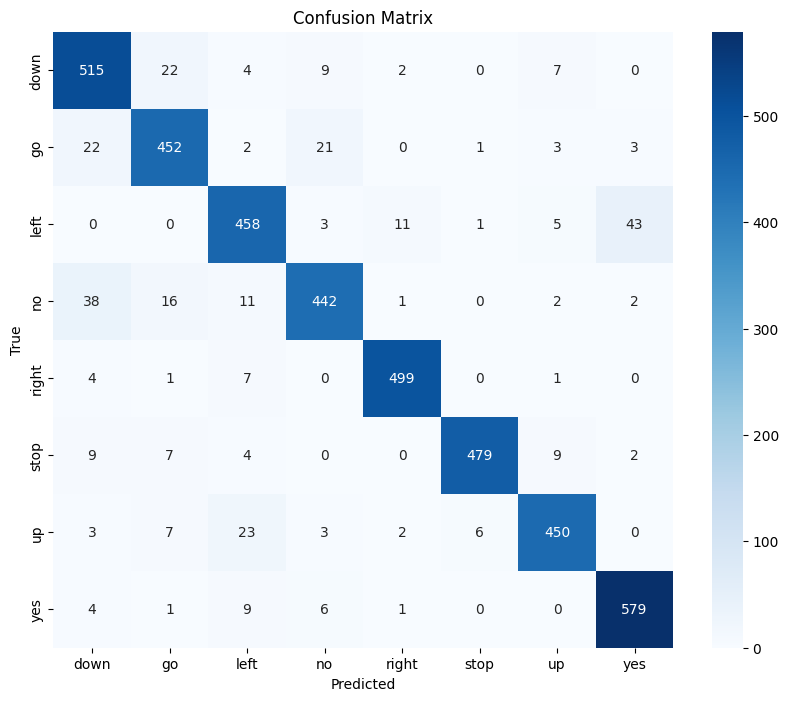

In [ ]:

y_pred = np.argmax(my_Recurrent_classifier.predict(X_test), axis=1)
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()


In [ ]:
%%timeit
my_Recurrent_classifier.predict(X_inv)

878/878 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step
878/878 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step
878/878 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step
878/878 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step
878/878 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step
878/878 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step
878/878 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step
878/878 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step
8.04 s ± 2.08 s per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [ ]:
8000/len(X_inv)

0.28493072621718846

In [ ]:
# RNN focuses on the temporal patterns